# 09 — Field results analysis

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495), Section **4.3**

## 1. Objective

Notebook 08 applied the frozen detector to the 141 pond samples and wrote what it found. This notebook asks what that output can and cannot support.

`[PAPER]` The article checks its presence-absence output against 18 manually labelled samples and reports a recall of 0.875, a precision of 1.000 and an accuracy of 0.966. **Those labels were not delivered**, so no such metrics are computed here, and nothing in this notebook should be read as one.

### What can be examined

1. **The output itself**: how many species are reported present, and how the detections are distributed over species, ponds and dates.
2. **Whether the output is plausible**: how the detector behaves on audio it was not calibrated on, which is mostly not frog calls.
3. **How much each result depends on choices that were made without field labels**: the thresholds and the shortest candidate that is allowed to count. These are varied, **not tuned**: the point is to see how stable the conclusions are.
4. **Whether the output carries any signal about the species**: the sidecars of some samples name the species that was heard, which is positive evidence only (an unnamed species is not an absent one). The detector either separates the samples that name a species from the rest or it does not.

The thresholds and the segmentation are not changed by anything here.

## 2. Load the field output

**What this section asks, and why it matters.** The tables of notebook 08, and the manifest that ties them to the detector and segmentation that produced them.

In [1]:
# Load the tables written by notebook 08 and the manifest of the run.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="ticks")
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 140)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
FIELD_DIR = REPO_ROOT / "data" / "processed" / "field_presence_absence"
for name in ("samples.csv", "presence.csv", "candidates.csv.gz", "run_log.csv", "run_manifest.json"):
    if not (FIELD_DIR / name).exists():
        raise FileNotFoundError(f"Missing {name}. Run notebook 08 first.")

samples = pd.read_csv(FIELD_DIR / "samples.csv", parse_dates=["date"])
presence = pd.read_csv(FIELD_DIR / "presence.csv", parse_dates=["date"])
candidates = pd.read_csv(FIELD_DIR / "candidates.csv.gz")
run_log = pd.read_csv(FIELD_DIR / "run_log.csv")
manifest = json.loads((FIELD_DIR / "run_manifest.json").read_text(encoding="utf-8"))

CODES = list(manifest["detector"]["thresholds"])
ALL_CODES = [f"f{i:02d}" for i in range(1, 11)]
candidates["margin"] = candidates.llr - candidates.threshold
sample_ids = samples.sample_id.tolist()

print("field output :", FIELD_DIR.relative_to(REPO_ROOT).as_posix())
print("samples      :", len(samples), "| candidates:", len(candidates), "| run-log rows:", len(run_log))
print("thresholds in the manifest match those used for the decisions:",
      bool(np.allclose(candidates.dropna(subset=["hypothesis"]).groupby("hypothesis").threshold.first().sort_index().to_numpy(),
                       [manifest["detector"]["thresholds"][c] for c in sorted(set(candidates.hypothesis.dropna()))])))
print("thresholds retuned on the ponds:", manifest["thresholds_retuned_on_ponds"], "| segmentation retuned on the ponds:", manifest["segmentation_retuned_on_ponds"])

field output : data/processed/field_presence_absence
samples      : 141 | candidates: 579540 | run-log rows: 141
thresholds in the manifest match those used for the decisions: True
thresholds retuned on the ponds: False | segmentation retuned on the ponds: False


`[OBSERVED]` The analysis reads **141 samples and 579,540 candidates**. The thresholds recorded in the manifest are the ones used for the decisions (True), and neither the thresholds nor the segmentation were retuned on the ponds (both False).

## 3. Presence by species

**What this section asks, and why it matters.** `[PAPER]` A species is present in a sample when at least one call is accepted. The share of the 141 samples in which each species is reported present, with a 95 % Wilson interval for the share. `f09` has no model and is `NA`.

,modelled,samples_present,share,wilson_low,wilson_high
code,,,,,
f01,True,18.0,0.128,0.082,0.193
f02,True,141.0,1.000,0.973,1.000
f03,True,100.0,0.709,0.630,0.778
f04,True,90.0,0.638,0.556,0.713
f05,True,57.0,0.404,0.327,0.487
f06,True,120.0,0.851,0.783,0.900
f07,True,62.0,0.440,0.360,0.522
f08,True,44.0,0.312,0.241,0.393
f09,False,NaN,NaN,NaN,NaN


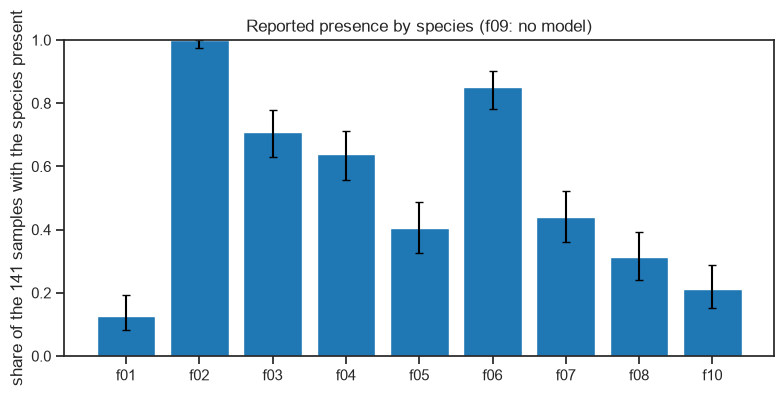

In [2]:
# Samples with each species present, and the Wilson 95 % interval of the share.
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


rows = []
for c in ALL_CODES:
    if c in CODES:
        k = int(presence[f"presence_{c}"].sum())
        lo, hi = wilson(k, len(presence))
        rows.append({"code": c, "modelled": True, "samples_present": k, "share": k / len(presence), "wilson_low": lo, "wilson_high": hi})
    else:
        rows.append({"code": c, "modelled": False, "samples_present": np.nan, "share": np.nan, "wilson_low": np.nan, "wilson_high": np.nan})
presence_summary = pd.DataFrame(rows).set_index("code")
display(presence_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
shown = presence_summary[presence_summary.modelled]
ax.bar(shown.index, shown.share, color="tab:blue")
ax.errorbar(shown.index, shown.share, yerr=[shown.share - shown.wilson_low, shown.wilson_high - shown.share], fmt="none", color="black", capsize=3)
ax.set(ylabel="share of the 141 samples with the species present", title="Reported presence by species (f09: no model)", ylim=(0, 1))
plt.tight_layout()
plt.show()

`[OBSERVED]` The reported presence is saturated for several species: `f02` in all 141 samples (Wilson interval 0.973 to 1.000), `f06` in 120 (0.783 to 0.900), `f03` in 100 (0.630 to 0.778) and `f04` in 90 (0.556 to 0.713). At the other end are `f01` (0.082 to 0.193) and `f10` (0.153 to 0.287).

`[INFERENCE]` The intervals describe the sampling uncertainty of a share, not the accuracy of the detector: they say nothing about how many of those presences are real.

## 4. Pond and date

**What this section asks, and why it matters.** `[PAPER]` The article reads the presence vectors over the five months and the two ponds, and reports more detections in Pond 1 than in Pond 2. The sidecars give each sample's pond and date, so the same view can be drawn. Descriptive only: the output is the detector's, not ground truth.

share of samples with each species present, by pond:


,presence_f01,presence_f02,presence_f03,presence_f04,presence_f05,presence_f06,presence_f07,presence_f08,presence_f10,samples
pond,,,,,,,,,,
P1,0.254,1.0,0.901,0.493,0.380,0.746,0.662,0.338,0.197,71
P2,0.000,1.0,0.515,0.779,0.426,0.956,0.221,0.294,0.221,68
NaN,0.000,1.0,0.500,1.000,0.500,1.000,0.000,0.000,0.500,2


by month:


,presence_f01,presence_f02,presence_f03,presence_f04,presence_f05,presence_f06,presence_f07,presence_f08,presence_f10,samples
month,,,,,,,,,,
April,0.086,1.0,0.657,0.400,0.371,0.714,0.257,0.200,0.343,35
August,0.294,1.0,0.824,0.735,0.353,0.912,0.529,0.353,0.000,34
February,0.000,1.0,0.647,0.353,0.529,0.882,0.588,0.118,0.294,17
July,0.000,1.0,0.500,0.846,0.654,0.885,0.577,0.077,0.269,26
September,0.185,1.0,0.889,0.778,0.185,0.889,0.370,0.778,0.185,27
NaN,0.000,1.0,0.500,1.000,0.500,1.000,0.000,0.000,0.500,2


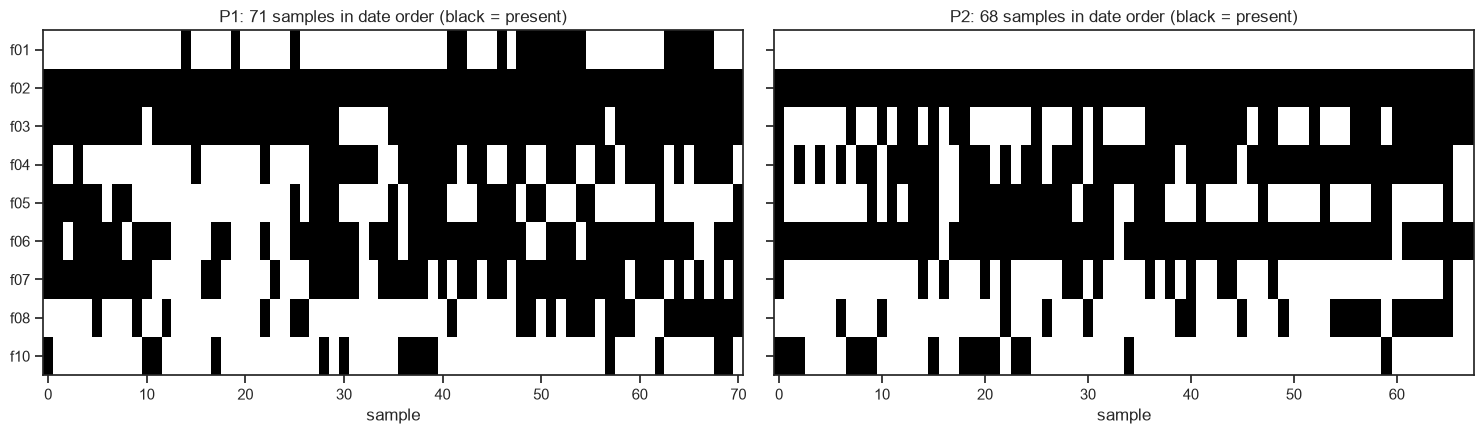

In [3]:
# Presence rate by pond and by month, and the species-by-date grid of each pond.
by_pond = presence.groupby("pond", dropna=False)[[f"presence_{c}" for c in CODES]].mean().assign(samples=presence.groupby("pond", dropna=False).size())
print("share of samples with each species present, by pond:")
display(by_pond.round(3))
by_month = presence.groupby("month", dropna=False)[[f"presence_{c}" for c in CODES]].mean().assign(samples=presence.groupby("month", dropna=False).size())
print("by month:")
display(by_month.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, pond in zip(axes, ("P1", "P2")):
    sub = presence[presence.pond == pond].sort_values("date")
    ax.imshow(sub[[f"presence_{c}" for c in CODES]].to_numpy().T, aspect="auto", cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
    ax.set_yticks(range(len(CODES)))
    ax.set_yticklabels(CODES)
    ax.set(title=f"{pond}: {len(sub)} samples in date order (black = present)", xlabel="sample")
plt.tight_layout()
plt.show()

`[OBSERVED]` By pond (71 samples from Pond 1 and 68 from Pond 2) the output differs clearly for some species: `f03` is present in 0.901 of the Pond 1 samples and 0.515 of Pond 2, `f07` in 0.662 and 0.221, `f01` in 0.254 and 0.000, while `f04` is the other way round (0.493 and 0.779) and `f06` is 0.746 and 0.956. `f02` is 1.0 in both.

`[OBSERVED]` By month, `f08` is present in 0.778 of the September samples and in between 0.077 and 0.353 of those of the other months, and `f01` in 0.000 of the February and July samples.

`[PAPER]` The article reports that `f01`, `f04`, `f08` and `f09` were absent from its manually labelled February samples. Here, in the 17 February samples, `f01` is reported in none, `f04` in 0.353 and `f08` in 0.118. The February samples that the article labelled are not identified here, so this is not a comparison with them.

## 5. What the detector accepts

**What this section asks, and why it matters.** One accepted candidate makes a species present, so what matters is how many candidates are accepted and to which species they go. Accepted candidates are also merged across the nine segmentation bands, because the same event can be proposed by several bands and would otherwise be counted several times.

In [4]:
# Candidates won and accepted by each species, accepted detections merged across bands, and the share of detections by pond.
valid = candidates[candidates.valid]
won = valid.groupby("hypothesis").agg(candidates=("llr", "size"), accepted=("accepted", "sum"), median_llr=("llr", "median"), median_margin_accepted=("margin", lambda m: m[m >= 0].median()))
won["share_of_candidates"] = won.candidates / won.candidates.sum()
won["acceptance"] = won.accepted / won.candidates
won["share_of_accepted"] = won.accepted / won.accepted.sum()
display(won.round(3).sort_values("accepted", ascending=False))


def merge_detections(frame: pd.DataFrame) -> int:
    """Number of distinct events after merging overlapping accepted candidates of one species."""
    starts, ends = frame.start_s.to_numpy(), frame.end_s.to_numpy()
    order = np.argsort(starts)
    events, current_end = 0, -np.inf
    for s, e in zip(starts[order], ends[order]):
        if s > current_end:
            events += 1
            current_end = e
        else:
            current_end = max(current_end, e)
    return events


accepted = valid[valid.accepted]
events = accepted.groupby(["sample_id", "hypothesis"]).apply(merge_detections, include_groups=False).rename("events").reset_index()
events = events.merge(samples[["sample_id", "pond"]], on="sample_id")
print("accepted candidates:", len(accepted), "| distinct events after merging across bands:", int(events.events.sum()))
by_pond_events = events.groupby(["pond", "hypothesis"]).events.sum().unstack(fill_value=0)
print("share of the distinct events of each species, by pond:")
display((by_pond_events.div(by_pond_events.sum(axis=1), axis=0)).round(3))
print("events per sample by pond:", (events.groupby("pond").events.sum() / samples.groupby("pond").size()).round(1).to_dict())

,candidates,accepted,median_llr,median_margin_accepted,share_of_candidates,acceptance,share_of_accepted
hypothesis,,,,,,,
f02,275884,250814,6.947,3.626,0.476,0.909,0.710
f03,195327,82808,6.350,3.130,0.337,0.424,0.234
f06,61811,10842,3.834,0.971,0.107,0.175,0.031
f05,5482,3020,5.931,2.010,0.009,0.551,0.009
f04,13195,2645,3.738,0.884,0.023,0.200,0.007
f07,6267,1382,3.654,1.751,0.011,0.221,0.004
f01,1354,941,10.122,3.282,0.002,0.695,0.003
f10,18748,574,3.881,0.962,0.032,0.031,0.002
f08,1472,406,5.140,1.980,0.003,0.276,0.001


accepted candidates: 353432 | distinct events after merging across bands: 95466
share of the distinct events of each species, by pond:


hypothesis,f01,f02,f03,f04,f05,f06,f07,f08,f10
pond,,,,,,,,,
P1,0.009,0.439,0.459,0.015,0.019,0.045,0.010,0.003,0.001
P2,0.000,0.829,0.008,0.023,0.007,0.121,0.001,0.004,0.008


events per sample by pond: {'P1': 913.3, 'P2': 441.2}


`[OBSERVED]` The **353,432 accepted candidates** are **95,466 distinct events** once overlapping candidates of the same species are merged across the nine bands. Pond 1 has **913.3 events per sample against 441.2 in Pond 2**.

`[OBSERVED]` In Pond 1 the events go mostly to `f03` (0.459) and `f02` (0.439), with 0.019 to `f05`. In Pond 2 they go to `f02` (0.829) and `f06` (0.121), with 0.008 to `f10`.

`[PAPER]` The article reports more detections in Pond 1 than in Pond 2, which is the same direction. For Pond 1 it reports *B. cinerascens* 58 %, *D. bifurcus* 23 % and *L. discodactylus* 17 %, and for Pond 2 mostly *D. bifurcus* and *E. petersi*: here the two leading species of Pond 1 are the same, `f05` is far lower and, in Pond 2, `f10` is almost absent.

`[INFERENCE]` The agreement in direction and in the two leading species of Pond 1 is encouraging but weak evidence: the numbers are counts of detections of a detector that, as shown below, also accepts a great deal that is not a call.

## 6. How the detector behaves on field audio

**What this section asks, and why it matters.** The detector was calibrated on calls of the nine species and on nothing else. In a pond almost every candidate is something else: other animals, rain, wind, water. A mixture model has no way to say "none of these": every candidate goes to the species whose model scores it highest, and the likelihood ratio can still be large
because the other models fit noise worse. The question is how much of the output that accounts for.

The calibration thresholds are shown next to the ratios of the accepted field candidates: a ratio only a little above a threshold set at the weakest calibration call is not much evidence of a call.

margin of the accepted candidates above the threshold (likelihood ratio minus threshold):


,threshold,count,10%,50%,90%
hypothesis,,,,,
f01,8.08,941.0,0.74,3.28,7.22
f02,3.70,250814.0,0.88,3.63,8.33
f03,6.94,82808.0,0.46,3.13,8.38
f04,5.06,2645.0,0.12,0.88,2.44
f05,5.55,3020.0,0.41,2.01,6.39
f06,5.23,10842.0,0.15,0.97,2.75
f07,5.75,1382.0,0.22,1.75,6.18
f08,7.19,406.0,0.29,1.98,5.91
f10,9.01,574.0,0.19,0.96,2.42


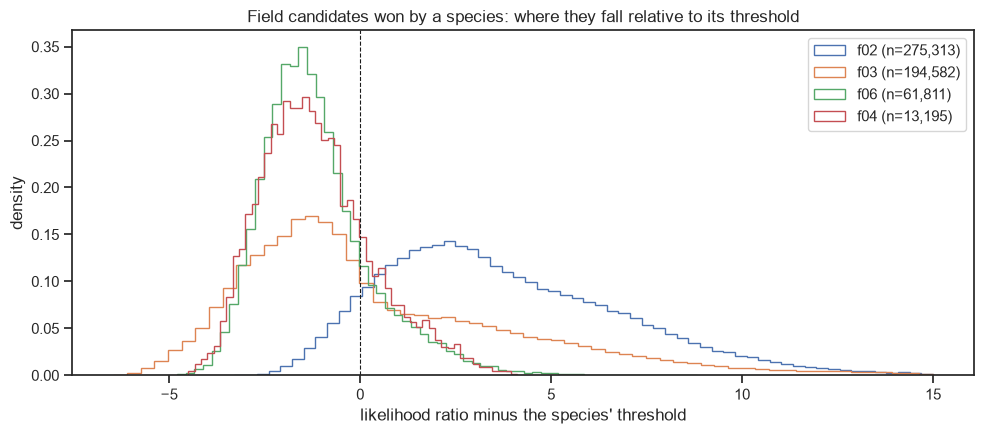

candidates shorter than 0.1 s: share of all valid candidates 0.11 | share of those accepted: 0.78 | acceptance of the others: 0.589


In [5]:
# Compare the field likelihood ratios of each species with its calibration threshold, and show their distribution.
thresholds = pd.Series(manifest["detector"]["thresholds"])
accepted_margin = accepted.groupby("hypothesis").margin.describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%"]]
accepted_margin.insert(0, "threshold", thresholds)
print("margin of the accepted candidates above the threshold (likelihood ratio minus threshold):")
display(accepted_margin.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in ("f02", "f03", "f06", "f04"):
    sub = valid[(valid.hypothesis == c) & (valid.margin > -10) & (valid.margin < 15)]
    ax.hist(sub.margin, bins=60, histtype="step", density=True, label=f"{c} (n={len(sub):,})")
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set(xlabel="likelihood ratio minus the species' threshold", ylabel="density", title="Field candidates won by a species: where they fall relative to its threshold")
ax.legend()
plt.tight_layout()
plt.show()

short = valid.duration_s < 0.1
print("candidates shorter than 0.1 s: share of all valid candidates", round(short.mean(), 3), "| share of those accepted:", round(valid[short].accepted.mean(), 3),
      "| acceptance of the others:", round(valid[~short].accepted.mean(), 3))

`[OBSERVED]` The accepted candidates of the species that are accepted most sit far above their thresholds: the median margin is 3.63 for `f02` and 3.13 for `f03`. For `f04`, `f06` and `f10` the median accepted candidate is only **0.88, 0.97 and 0.96** above its threshold, and the 10th percentile 0.12 to 0.15 for `f04` and `f06`.

`[OBSERVED]` Candidates shorter than 0.1 seconds are 11.0 % of the valid ones and **78.0 % of them are accepted**, against 58.9 % of the others.

`[INFERENCE]` For `f04`, `f06` and `f10` an accepted candidate is barely more convincing than the weakest calibration call, so it is weak evidence of a call. Very short candidates, which notebook 07 showed are almost never calls, are accepted *more* often, as expected of a mean score taken over a handful of frames.

## 7. How much do the results depend on the thresholds?

**What this section asks, and why it matters.** The thresholds sit at the weakest calibration call of each species, with frog calls as the only negatives. Raising every threshold by the same amount `delta` asks how the presence output changes if a little more evidence were required. This is not a tuning: no value of `delta` is chosen or recommended.
It shows how stable each species' result is.

hypothesis,f01,f02,f03,f04,f05,f06,f07,f08,f10
delta,,,,,,,,,
0,0.128,1.000,0.709,0.638,0.404,0.851,0.440,0.312,0.213
1,0.113,0.993,0.617,0.376,0.199,0.787,0.340,0.241,0.184
2,0.113,0.993,0.574,0.177,0.099,0.638,0.270,0.184,0.099
3,0.106,0.993,0.511,0.106,0.064,0.454,0.206,0.163,0.057
5,0.092,0.993,0.433,0.007,0.028,0.220,0.092,0.106,0.035
8,0.057,0.965,0.383,0.000,0.014,0.007,0.035,0.050,0.021


samples with at least one species present: {0: 141, 1: 141, 2: 141, 3: 141, 5: 140, 8: 136}


median number of species present per sample: {0: 5.0, 1: 4.0, 2: 3.0, 3: 3.0, 5: 2.0, 8: 1.0}


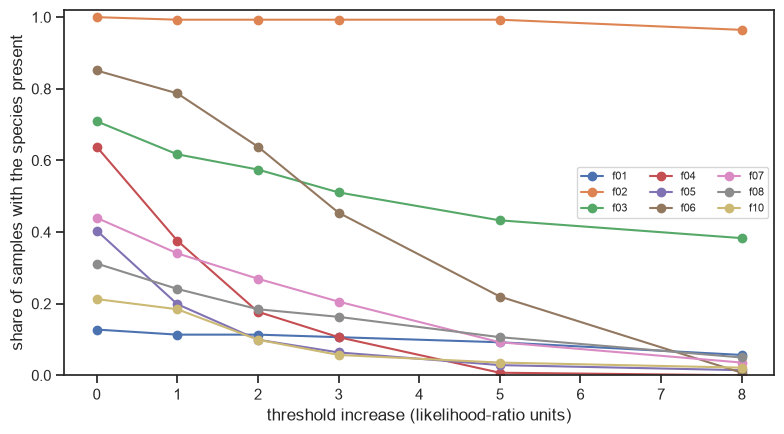

In [6]:
# Presence share of every species when all thresholds are raised by delta likelihood-ratio units.
DELTAS = (0, 1, 2, 3, 5, 8)


def presence_under(delta=0.0, min_duration=0.0):
    """Boolean table of samples by modelled species: at least one candidate above threshold + delta and at least min_duration long."""
    c = valid[(valid.duration_s >= min_duration) & (valid.margin >= delta)]
    return (c.groupby(["sample_id", "hypothesis"]).size().unstack(fill_value=0)
            .reindex(index=sample_ids, columns=CODES, fill_value=0) > 0)


delta_table = pd.DataFrame({delta: presence_under(delta).mean() for delta in DELTAS}).T
delta_table.index.name = "delta"
display(delta_table.round(3))
print("samples with at least one species present:", {d: int(presence_under(d).any(axis=1).sum()) for d in DELTAS})
print("median number of species present per sample:", {d: float(presence_under(d).sum(axis=1).median()) for d in DELTAS})

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in CODES:
    ax.plot(DELTAS, delta_table[c], marker="o", label=c)
ax.set(xlabel="threshold increase (likelihood-ratio units)", ylabel="share of samples with the species present", ylim=(0, 1.02))
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

`[OBSERVED]` Raising every threshold changes the species very differently. For `f04` the share of samples falls from 0.638 to 0.376 with an increase of 1, 0.177 with 2, 0.007 with 5 and 0.000 with 8; for `f06` from 0.851 to 0.220 with 5 and 0.007 with 8; for `f05` from 0.404 to 0.028 with 5.
`f02` hardly moves: 0.993 up to an increase of 5 and still **0.965 with 8**; `f03` goes from 0.709 to 0.383 with 8.

`[OBSERVED]` The median number of species present per sample falls from 5.0 to 3.0 with an increase of 2 or 3, and to 1.0 with 8. Some species is still reported in 141 samples with an increase of 3 and in 136 with 8.

`[INFERENCE]` The presence of `f04`, `f06`, `f05`, `f07` and `f10` depends almost entirely on candidates that are only a little above their thresholds, so it is highly sensitive to a choice that was made without field labels. The presence of `f02` does not depend on it at all in this range: its accepted candidates have ratios far above anything the
calibration needed, which a threshold change of this size cannot remove.

## 8. How much do they depend on the shortest candidate?

**What this section asks, and why it matters.** The front end allows candidates of a few hundredths of a second, and notebook 07 showed that candidates that short almost never overlap an annotated call. The article relates its moving average to the shortest call it segments but enforces no minimum.
Requiring a minimum duration is **not** part of the article and is not adopted: this asks only how many of the presence calls rest on very short candidates.

In [7]:
# Presence share of every species when candidates shorter than a minimum duration are ignored.
MIN_DURATIONS = (0.0, 0.05, 0.1, 0.2, 0.3)
duration_table = pd.DataFrame({m: presence_under(0.0, m).mean() for m in MIN_DURATIONS}).T
duration_table.index.name = "min_duration_s"
display(duration_table.round(3))
print("median number of species present per sample:", {m: float(presence_under(0.0, m).sum(axis=1).median()) for m in MIN_DURATIONS})

both = pd.DataFrame({f"delta={d}, min={m}s": presence_under(d, m).mean() for d in (0, 2) for m in (0.0, 0.2)}).T
print("thresholds raised and short candidates ignored together:")
display(both.round(3))

hypothesis,f01,f02,f03,f04,f05,f06,f07,f08,f10
min_duration_s,,,,,,,,,
0.00,0.128,1.000,0.709,0.638,0.404,0.851,0.440,0.312,0.213
0.05,0.113,1.000,0.688,0.589,0.404,0.830,0.440,0.305,0.199
0.10,0.099,0.993,0.574,0.475,0.298,0.780,0.348,0.206,0.078
0.20,0.007,0.993,0.390,0.000,0.213,0.376,0.064,0.007,0.035
0.30,0.000,0.993,0.291,0.000,0.135,0.220,0.035,0.000,0.007


median number of species present per sample: {0.0: 5.0, 0.05: 5.0, 0.1: 4.0, 0.2: 2.0, 0.3: 2.0}


thresholds raised and short candidates ignored together:


hypothesis,f01,f02,f03,f04,f05,f06,f07,f08,f10
"delta=0, min=0.0s",0.128,1.000,0.709,0.638,0.404,0.851,0.440,0.312,0.213
"delta=0, min=0.2s",0.007,0.993,0.390,0.000,0.213,0.376,0.064,0.007,0.035
"delta=2, min=0.0s",0.113,0.993,0.574,0.177,0.099,0.638,0.270,0.184,0.099
"delta=2, min=0.2s",0.000,0.957,0.270,0.000,0.071,0.000,0.007,0.000,0.014


`[OBSERVED]` Ignoring candidates shorter than 0.2 seconds changes the presence a great deal: `f04` goes from 0.638 to **0.000**, `f01` from 0.128 to 0.007, `f08` from 0.312 to 0.007, `f07` from 0.440 to 0.064 and `f10` from 0.213 to 0.035, while `f06` goes to 0.376 and `f03` to 0.390. **`f02` stays at 0.993**, also with a minimum of 0.3 seconds.
The median number of species present per sample falls from 5.0 to 2.0.

`[OBSERVED]` Raising the thresholds by 2 and ignoring candidates shorter than 0.2 seconds together leaves `f02` at 0.957, `f03` at 0.270 and `f06`, `f04` and `f08` at 0.000.

`[INFERENCE]` All of the field presence of `f04` rests on candidates shorter than 0.2 seconds, which notebook 07 showed are rarely calls. `f01`, `f08` and, for the article's labelled samples, `f04` are the species whose presence the article reports as absent: they are also the ones whose presence collapses when very short candidates are ignored. That agreement is suggestive but proves nothing, because the
rule was not validated. The `f02` result is not an artefact of fragments: its presence rests on long candidates.

## 9. Does the output carry any signal about the species?

**What this section asks, and why it matters.** For some samples the sidecars name the species that was heard. That is positive evidence only: a species that is not named may well be present. Even so, it gives a test that needs no labelled negatives. If the detector carries information about a species, the samples that name it should have more evidence
of it than the others, whatever the absolute level of the output. That is measured with the area under the ROC curve of a per-sample score (the strongest margin of an accepted-or-not candidate that the species wins) for *named against not named*, which is a lower bound on the discrimination because some of the not-named samples do contain the species.

A value of 0.5 means no signal. The detector's presence call is also compared between the two groups.

In [8]:
# Per species: presence among the samples that name it and among the others, and the AUC of the strongest margin for named versus not named.
named = pd.DataFrame({c: samples.named_modelled.fillna("").str.split(",").map(lambda cs: c in cs) for c in CODES})
named.index = samples.sample_id
best_margin = (valid.groupby(["sample_id", "hypothesis"]).margin.max().unstack().reindex(index=sample_ids, columns=CODES))
base_presence = presence_under(0.0)

rows = []
for c in CODES:
    y = named[c].to_numpy()
    score = best_margin[c].fillna(-50).to_numpy()
    rows.append({"code": c, "samples_naming_it": int(y.sum()), "present_among_named": base_presence.loc[y, c].mean() if y.any() else np.nan,
                 "present_among_not_named": base_presence.loc[~y, c].mean(),
                 "auc_named_vs_not": roc_auc_score(y, score) if 3 <= y.sum() < len(y) else np.nan})
signal = pd.DataFrame(rows).set_index("code")
signal["lift"] = signal.present_among_named / signal.present_among_not_named
display(signal.round(3))
print("samples that name at least one modelled species:", int(named.any(axis=1).sum()), "of", len(named))

,samples_naming_it,present_among_named,present_among_not_named,auc_named_vs_not,lift
code,,,,,
f01,0,NaN,0.128,NaN,NaN
f02,52,1.0,1.000,0.547,1.000
f03,40,1.0,0.594,0.929,1.683
f04,0,NaN,0.638,NaN,NaN
f05,0,NaN,0.404,NaN,NaN
f06,1,1.0,0.850,NaN,1.176
f07,0,NaN,0.440,NaN,NaN
f08,0,NaN,0.312,NaN,NaN
f10,4,0.5,0.204,0.566,2.446


samples that name at least one modelled species: 89 of 141


In [9]:
# Repeat the same comparison when the thresholds are raised and the shortest candidates ignored.
strict_rows = []
for delta, minimum in ((0, 0.0), (3, 0.0), (0, 0.2), (3, 0.2)):
    pres = presence_under(delta, minimum)
    for c in CODES:
        y = named[c].to_numpy()
        if y.sum() >= 3:
            strict_rows.append({"delta": delta, "min_duration_s": minimum, "code": c, "present_among_named": pres.loc[y, c].mean(),
                                "present_among_not_named": pres.loc[~y, c].mean()})
strict = pd.DataFrame(strict_rows)
display(strict.pivot(index=["delta", "min_duration_s"], columns="code", values="present_among_named").round(2).rename_axis(columns="present among named samples"))
display(strict.pivot(index=["delta", "min_duration_s"], columns="code", values="present_among_not_named").round(2).rename_axis(columns="present among the others"))

present among named samples  f02   f03   f10
delta min_duration_s                        
0     0.0                    1.0  1.00  0.50
      0.2                    1.0  0.95  0.50
3     0.0                    1.0  0.98  0.25
      0.2                    0.9  0.35  0.00

present among the others   f02   f03   f10
delta min_duration_s                      
0     0.0                 1.00  0.59  0.20
      0.2                 0.99  0.17  0.02
3     0.0                 0.99  0.33  0.05
      0.2                 0.84  0.07  0.01

`[OBSERVED]` For **`f03`**, named in 40 samples, the detector reports presence in **1.000 of the samples that name it and 0.594 of the others**, and the strongest margin separates the two groups with an area under the ROC curve of **0.929**. Requiring candidates of at least 0.2 seconds, `f03` is present in **0.95** of the samples that name it and **0.17** of the others;
with the thresholds also raised by 3 the shares are 0.35 and 0.07.

`[OBSERVED]` For **`f02`**, named in 52 samples, the presence is **1.000 among the samples that name it and 1.000 among the others**, and the area under the curve is **0.547**, close to chance. With the thresholds raised by 3 and candidates under 0.2 seconds ignored it is still 0.90 and 0.84.

`[OBSERVED]` `f10` is named in 4 samples: 0.50 present among them and 0.204 among the others (area 0.566). `f06` is named in 1 sample. **No sample names `f01`, `f04`, `f05`, `f07` or `f08`**, so nothing can be tested for them.

`[INFERENCE]` The `f03` output carries real information about the species, since the samples that name it have much stronger evidence of it than the rest, and an unnamed sample may still contain it, so the true separation is at least this good. The `f02` output carries none that this test can see: whatever the detector reports for `f02` is the same
with or without the species being named. Of the species that cannot be tested, `f04` has the weakest accepted evidence and the presence that collapses most under the checks of the previous sections, and `f01` and `f08` collapse under the minimum-duration check.

## 10. Save the analysis tables

**What this section asks, and why it matters.** The tables behind the figures above, so that the analysis can be inspected without rerunning it.

In [10]:
# Write the analysis tables, and list only the files this notebook wrote.
OUTPUTS = {
    "analysis_presence_summary.csv": presence_summary.reset_index(), "analysis_presence_by_pond.csv": by_pond.reset_index(),
    "analysis_presence_by_month.csv": by_month.reset_index(), "analysis_candidates_by_hypothesis.csv": won.reset_index(),
    "analysis_accepted_margins.csv": accepted_margin.reset_index(), "analysis_events_by_sample_species.csv": events,
    "analysis_threshold_sensitivity.csv": delta_table.reset_index(), "analysis_min_duration_sensitivity.csv": duration_table.reset_index(),
    "analysis_named_species_signal.csv": signal.reset_index(), "analysis_named_species_strict.csv": strict,
}
for name, table in OUTPUTS.items():
    table.to_csv(FIELD_DIR / name, index=False)
print("written to", FIELD_DIR.relative_to(REPO_ROOT).as_posix())
for name in OUTPUTS:
    print(f"  {name:<44} {(FIELD_DIR / name).stat().st_size / 1e6:>7.3f} MB")

written to data/processed/field_presence_absence
  analysis_presence_summary.csv                  0.001 MB
  analysis_presence_by_pond.csv                  0.000 MB
  analysis_presence_by_month.csv                 0.001 MB
  analysis_candidates_by_hypothesis.csv          0.001 MB
  analysis_accepted_margins.csv                  0.001 MB
  analysis_events_by_sample_species.csv          0.025 MB
  analysis_threshold_sensitivity.csv             0.001 MB
  analysis_min_duration_sensitivity.csv          0.001 MB
  analysis_named_species_signal.csv              0.000 MB
  analysis_named_species_strict.csv              0.000 MB


## 11. Conclusions and limitations

**What this notebook delivers.** An examination of what the field output supports, with the sampling uncertainty of the presence shares, the pond and date structure, the species that the detections go to, the dependence of the result on the thresholds and on the shortest candidate counted, and a test against the species named in the sidecars. The tables are in
`data/processed/field_presence_absence`. **No accuracy, precision or recall is computed**: the article's 18 labelled vectors were not delivered.

**What was found.**

1. **The presence output is saturated and mostly uninformative.** `f02` is reported in every sample, whether or not its sidecars name it (the area under the curve is 0.547), and it is still in 96.5 % of the samples with the thresholds raised by 8.
2. **For `f03` the output does carry information.** The samples that name it have much stronger evidence of it than the others (0.929), and requiring candidates of at least 0.2 seconds keeps 0.95 of the named samples while lowering the others from 0.59 to 0.17.
3. **The presence of `f04`, `f06`, `f05`, `f07` and `f10` hangs on candidates barely above their thresholds**, and that of `f04` entirely on candidates shorter than 0.2 seconds.
4. **Pond 1 has about twice the events of Pond 2** (913.3 and 441.2 per sample), as in the article, and the two leading species of Pond 1 are the article's.
5. **The result depends strongly on two choices that were made without field labels**: the thresholds, and whether very short candidates count.

**What cannot be concluded.** That any species is present or absent in any sample; that the detector generalises to the field with the accuracy of the article; or that the order of the species by presence reflects the community. The test against the sidecars covers `f03` and `f02` convincingly, `f10` and `f06` barely, and the other five species not at all.

**Decisions taken here.** The thresholds and the minimum duration are **varied, not tuned**: no value is chosen or recommended, and the reported presence is that of the frozen detector without changes.

**Limitations.**

- **No labels for the field**, so nothing here is an accuracy.
- **The sidecars are positive evidence only** and name four species, so unnamed samples are not negatives.
- **The detector has no model of non-frog sound** and was calibrated against frog calls only, which is the cause of the behaviour examined in sections 5 to 8, not a fault of the analysis.
- **One accepted candidate declares presence**, so the output is as sensitive as the worst false-alarm rate of each species.
- **The article's own February samples are not identified**, so the comparison with its absences is indirect.

**What this means for the replication.** The pipeline of the article runs end to end on its own test material, and it is the *calibration against annotated field samples*, the step that could not be reproduced, that the article relied on to control exactly what this notebook finds uncontrolled. Reproducing it needs the labelled samples.